In [ ]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

In [ ]:
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float
    M: int

with open('../../FBAsolution/all_samples_wo_normalize.pkl', 'rb') as f:
    data = pickle.load(f)
    samples = data['samples1']
    samples2 = data['samples2']
    samples3 = data['samples3']
    samples4 = data['samples4']
total_samples = samples + samples2 + samples3 + samples4

Node 0: Spearman correlation = 0.2308, p-value = 9.5292e-04
Node 1: Spearman correlation = 0.1545, p-value = 2.8093e-02
Node 2: Spearman correlation = 0.2705, p-value = 9.8696e-05
Node 3: Spearman correlation = 0.3118, p-value = 6.2673e-06
Node 4: Spearman correlation = 0.2176, p-value = 1.8681e-03
Node 5: Spearman correlation = 0.1886, p-value = 7.1866e-03
Node 6: Spearman correlation = 0.0207, p-value = 7.7010e-01
Node 7: Spearman correlation = 0.3193, p-value = 3.6346e-06
Node 8: Spearman correlation = 0.1927, p-value = 6.0046e-03
Node 9: Spearman correlation = 0.4161, p-value = 7.3518e-10
Node 10: Spearman correlation = 0.3200, p-value = 3.4419e-06
Node 11: Spearman correlation = -0.1213, p-value = 8.5561e-02
Node 12: Spearman correlation = -0.0940, p-value = 1.8349e-01
Node 13: Spearman correlation = 0.1534, p-value = 2.9268e-02
Node 14: Spearman correlation = 0.5939, p-value = 1.8909e-20
Node 15: Spearman correlation = 0.2759, p-value = 7.0412e-05
Node 16: Spearman correlation = 

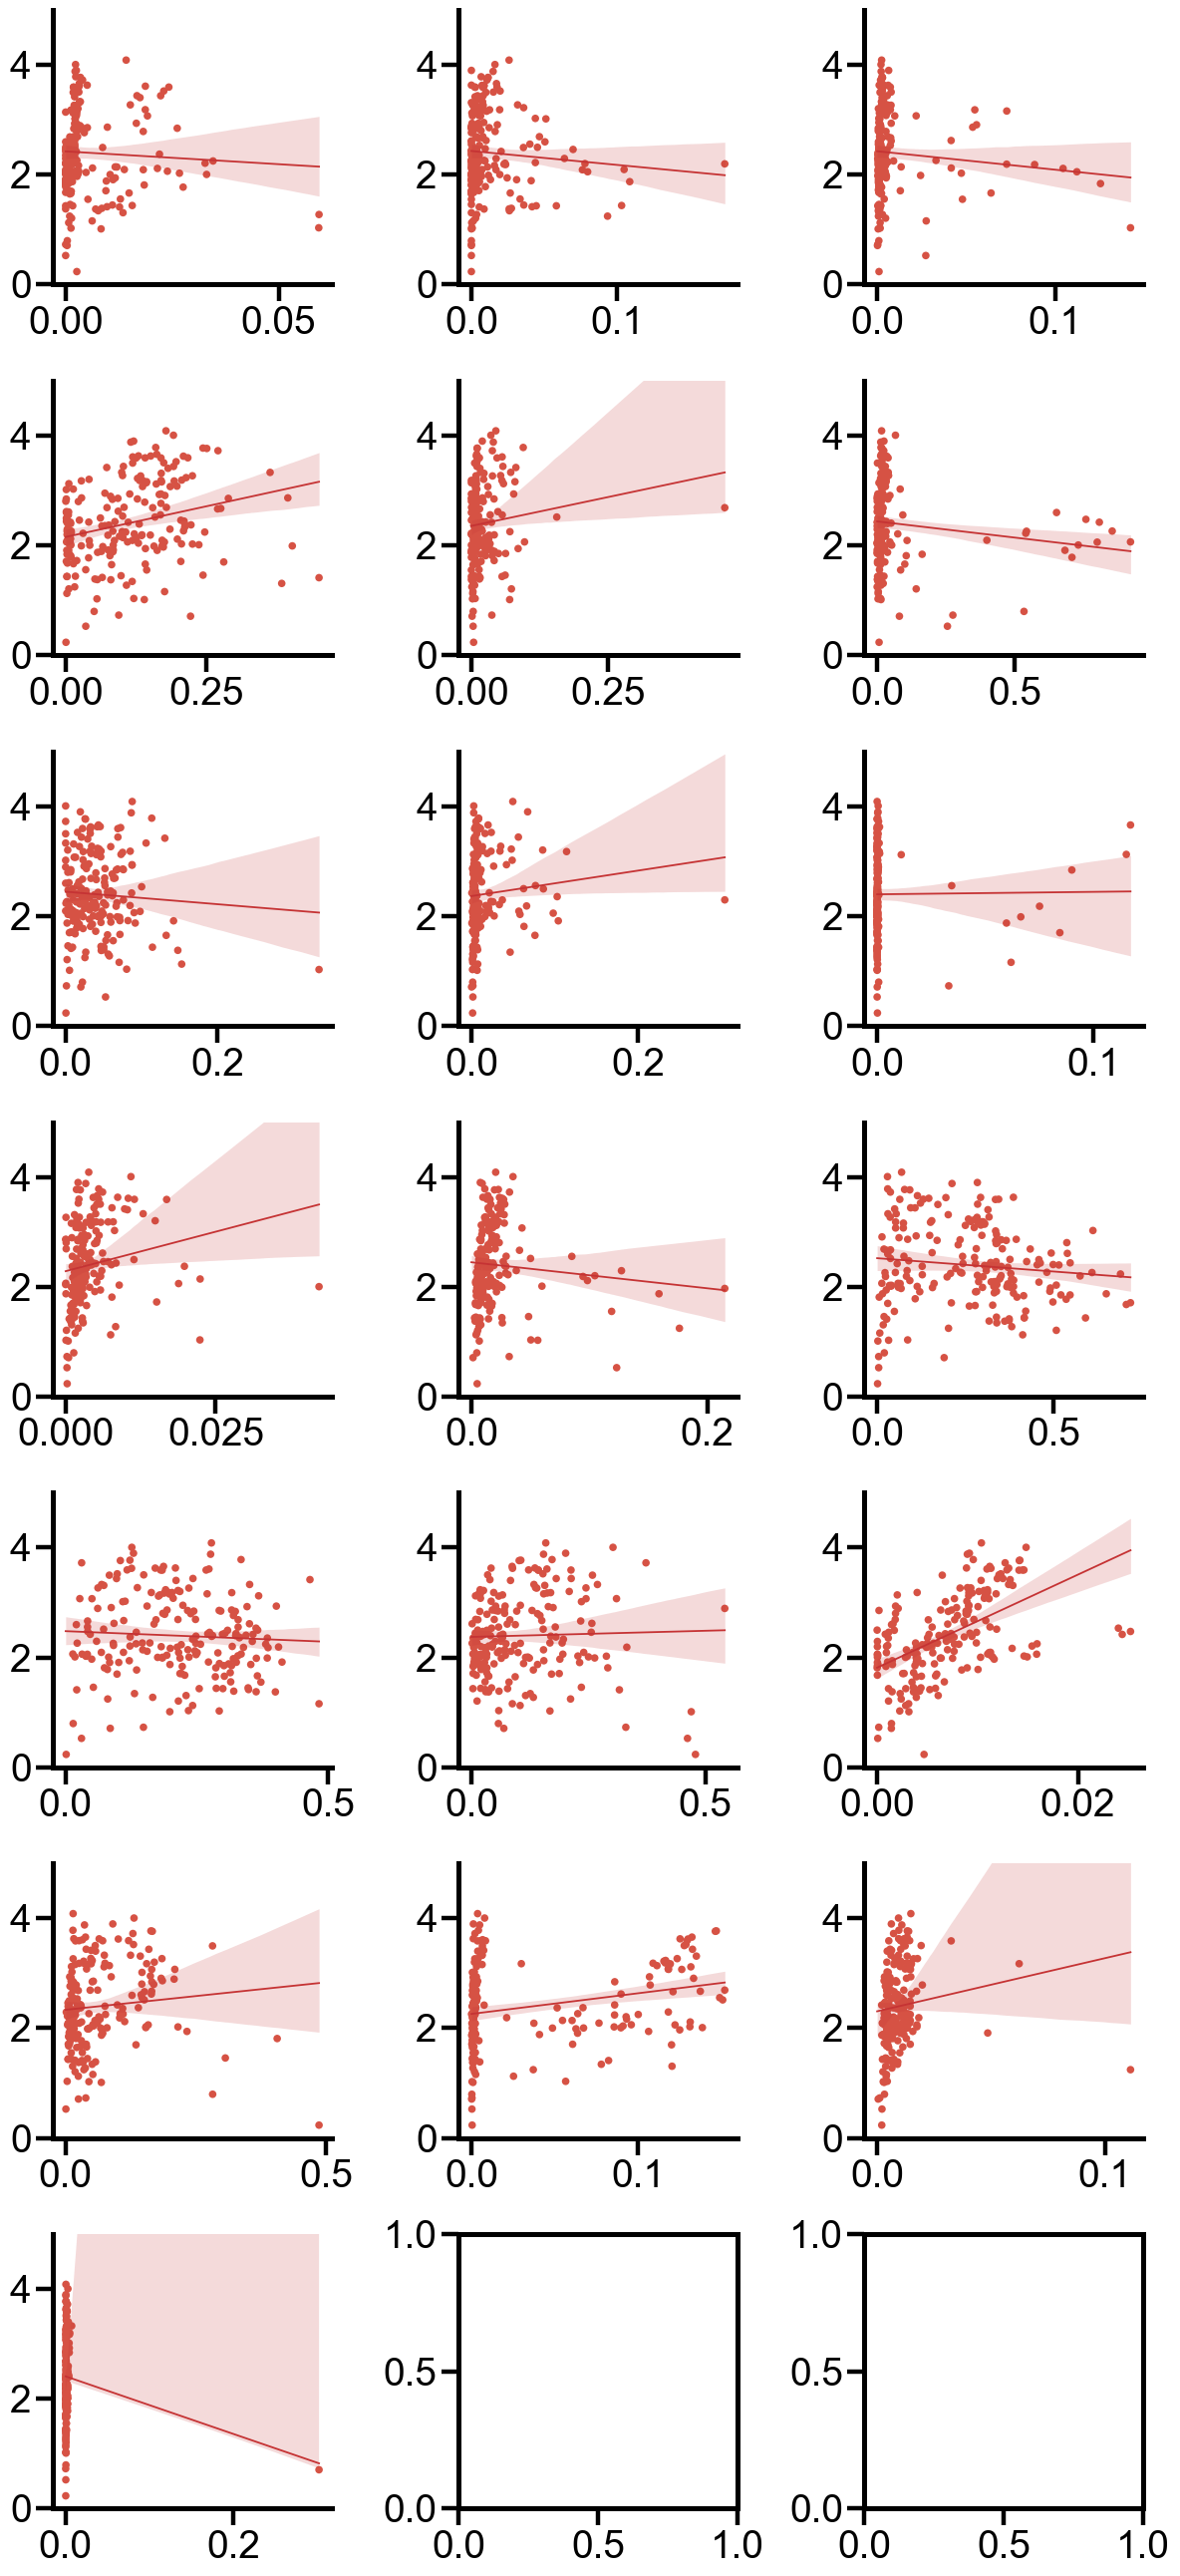

In [ ]:
set_panel_style(scale=4)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
from scipy.stats import spearmanr

X = samples4

cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]
complex_line_color = colors[19]
complex_scatter_color = colors[18]


corr_in_silico_complex = []

fig, axes = plt.subplots(7, 3, figsize=(12, 26))   # 调整整体尺寸
axes = axes.flatten()  



rng = np.random.default_rng(0)

for i in range(19):

    ax = axes[i]
    x = np.array([x.E for x in X]).T[i]
    y = np.array([x.Y for x in X])

    if i == 14:
        mask = np.isfinite(x) & np.isfinite(y) & (x < 0.03)
        x, y = x[mask], y[mask]

    rho, p = spearmanr(x, y)
    print(f"Node {i}: Spearman correlation = {rho:.4f}, p-value = {p:.4e}")
    corr_in_silico_complex.append((rho, p))

    # ---------- OLS ----------
    m, b = np.polyfit(x, y, deg=1)

    xg = np.linspace(0, x.max(), 200)
    yg = m * xg + b

    # ---------- bootstrap CI ----------
    B = 2000
    n = x.size
    Yhat = np.empty((B, xg.size))

    for j in range(B):
        idx = rng.integers(0, n, n)
        m_i, b_i = np.polyfit(x[idx], y[idx], deg=1)
        Yhat[j] = m_i * xg + b_i

    lo, hi = np.percentile(Yhat, [2.5, 97.5], axis=0)

    # ---------- plot ----------
    ax.scatter(
        x, y,
        s=30,
        color=complex_scatter_color,
        edgecolors="none"
    )

    ax.plot(
        xg, yg,
        linewidth=1.3,
        color=complex_line_color
    )

    ax.fill_between(
        xg, lo, hi,
        alpha=0.18,
        color=complex_line_color,
        linewidth=0
    )

    #ax.set_xlabel(f"E_{i}")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    #ax.grid(True, alpha=0.3)

    #ax.set_xlim(0, 1.05 * x.max())
    ax.set_ylim(0, 5)


plt.tight_layout(w_pad=1.5, h_pad=1.5)
# fig.savefig(f"Supp_Figure4a.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()